<a href="https://colab.research.google.com/github/Rishikaj03/GenAI/blob/main/GenAIPractical6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
torch.manual_seed(42)

# 1. Define the input tokens and basic dimensions
tokens = ["The", "cat", "sat","on","the","mat"]
seq_len = len(tokens)

# Let's define embedding dimension (d_model) and projection dimensions (d_k, d_v)
d_model = 16
d_k = 8
d_v = 8

In [15]:
# 2. Initialize toy embeddings for our tokens
# In a real model, these would come from an embedding layer or previous encoder layer
embeddings = torch.randn(seq_len, d_model)
print("Input Embeddings (Hidden States):")
for token, emb in zip(tokens, embeddings):
    print(f"{token}: {emb[:4].tolist()}... (dimension: {d_model})")

Input Embeddings (Hidden States):
The: [1.9269152879714966, 1.4872840642929077, 0.9007171988487244, -2.1055209636688232]... (dimension: 16)
cat: [1.6423169374465942, -0.1595974713563919, -0.4973975419998169, 0.439589262008667]... (dimension: 16)
sat: [-1.3846737146377563, -0.8712361454963684, -0.223365917801857, 1.7173614501953125]... (dimension: 16)
on: [-0.9138230085372925, -0.6581372618675232, 0.07802387326955795, 0.5258087515830994]... (dimension: 16)
the: [1.4451338052749634, 0.8564125299453735, 2.218075752258301, 0.5231655240058899]... (dimension: 16)
mat: [0.01086814422160387, -0.33874234557151794, -1.3406795263290405, -0.5853705406188965]... (dimension: 16)


In [16]:
# 3. Define Query (Q), Key (K), and Value (V) projection matrices
W_q = torch.randn(d_model, d_k)
W_k = torch.randn(d_model, d_k)
W_v = torch.randn(d_model, d_v)

Q = torch.matmul(embeddings, W_q)
K = torch.matmul(embeddings, W_k)
V = torch.matmul(embeddings, W_v)

print("\nQuery (Q) Shape:", Q.shape)
print("Key (K) Shape:", K.shape)
print("Value (V) Shape:", V.shape)


Query (Q) Shape: torch.Size([6, 8])
Key (K) Shape: torch.Size([6, 8])
Value (V) Shape: torch.Size([6, 8])


In [17]:
# 4. Raw Attention Scores (Q * K^T)
attn_scores = torch.matmul(Q, K.transpose(0, 1))

# 5. Attention Distribution (Softmax)
attn_distribution = F.softmax(attn_scores, dim=-1)

print("Attention Scores:\n", attn_scores.numpy())
print("\nAttention Distribution (Softmax weights):\n", attn_distribution.numpy())

Attention Scores:
 [[ 24.92842     3.491169  -15.822372    1.6174488  53.155067  -14.111511 ]
 [122.41314   -45.10624    40.0733     -4.9569664  25.818409   55.957745 ]
 [ 58.43605    74.71451    15.910805  -28.99971    68.63028   -30.05977  ]
 [122.36368    41.58553    59.367523  -46.660404   54.287064    8.305082 ]
 [ 77.59124    -5.5329437   7.622402  -20.492977   65.30603    -6.0425634]
 [-50.946022  -23.972332   12.409223   39.34651   -65.79714    26.847279 ]]

Attention Distribution (Softmax weights):
 [[5.5121673e-13 2.6992490e-22 1.1052957e-30 4.1447257e-23 1.0000000e+00
  6.1164025e-30]
 [1.0000000e+00 0.0000000e+00 1.7388423e-36 0.0000000e+00 1.1210388e-42
  1.3765345e-29]
 [8.4989878e-08 9.9772650e-01 2.8899321e-26 1.4012985e-45 2.2733412e-03
  0.0000000e+00]
 [1.0000000e+00 8.2888473e-36 4.3764062e-28 0.0000000e+00 2.7208338e-30
  0.0000000e+00]
 [9.9999535e-01 7.9364030e-37 4.1012495e-31 2.5223372e-43 4.6195451e-06
  4.7675833e-37]
 [6.1157429e-40 3.1693770e-28 2.0011605e-

In [18]:
# 6. Calculate Final Attention Output Vectors
attention_output = torch.matmul(attn_distribution, V)

print("Output Attention Vectors Shape:", attention_output.shape)
for token, val in zip(tokens, attention_output):
    print(f"{token} attention vector: {val.tolist()}")

Output Attention Vectors Shape: torch.Size([6, 8])
The attention vector: [-2.0167057514190674, 2.291747570037842, 5.811694145202637, 3.895228862762451, -4.559354305267334, -4.211328506469727, -0.41588258743286133, 10.73759937286377]
cat attention vector: [-2.074540853500366, 13.131219863891602, 5.859034538269043, -4.5780863761901855, 2.442117214202881, -4.097280979156494, 1.6863069534301758, 7.737551689147949]
sat attention vector: [-1.4540940523147583, -9.76275634765625, -0.5561679005622864, -0.632067859172821, 3.408661365509033, 0.08258470147848129, 1.3049662113189697, 2.42619252204895]
on attention vector: [-2.074540853500366, 13.131219863891602, 5.859034538269043, -4.5780863761901855, 2.442117214202881, -4.097280979156494, 1.6863069534301758, 7.737551689147949]
the attention vector: [-2.074540615081787, 13.131169319152832, 5.859034061431885, -4.578046798706055, 2.442084789276123, -4.097281455993652, 1.6862971782684326, 7.737565517425537]
mat attention vector: [-3.0037429332733154, 

Text(45.722222222222214, 0.5, 'Queries (Target Tokens)')

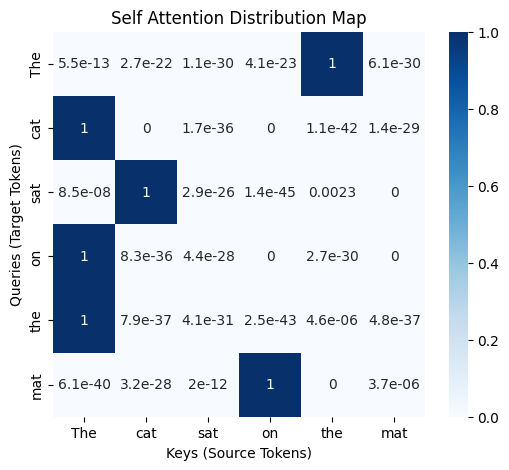

In [19]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    attn_distribution.detach().numpy(),
    annot=True,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="Blues",
    cbar=True,
    vmin=0,
    vmax=1
)

plt.title("Self Attention Distribution Map")
plt.xlabel("Keys (Source Tokens)")
plt.ylabel("Queries (Target Tokens)")

In [20]:
# Explicitly show the math for step by step computation

for i, q_token in enumerate(tokens):
  print(f"\n--- Calculation for Query token: '{q_token.strip()}' ----")
  q_vec = Q[i]

  raw_scores = []
  scaled_scores = []

  for j, k_token in enumerate(tokens):
    k_vec = K[j]
    dot_prod = torch.dot(q_vec, k_vec).item()
    # Standard scaling factor for transformer attention is sqrt(d_k)
    scaled_prod = dot_prod / np.sqrt(d_k)

    raw_scores.append(dot_prod)
    scaled_scores.append(scaled_prod)

    print(f"  Key '{k_token.strip()}': Raw Score = {dot_prod:.4f}, Scaled Score = {scaled_prod:.4f}")

  # Compute manual Softmax
  exp_scores = np.exp(scaled_scores)
  sum_exp = np.sum(exp_scores)
  probabilities = exp_scores / sum_exp

  print(f"  Softmax Distribution:")
  for j, k_token in enumerate(tokens):
    print(f"    to '{k_token.strip()}': {probabilities[j]:.4f}")


--- Calculation for Query token: 'The' ----
  Key 'The': Raw Score = 24.9284, Scaled Score = 8.8135
  Key 'cat': Raw Score = 3.4912, Scaled Score = 1.2343
  Key 'sat': Raw Score = -15.8224, Scaled Score = -5.5941
  Key 'on': Raw Score = 1.6174, Scaled Score = 0.5719
  Key 'the': Raw Score = 53.1551, Scaled Score = 18.7932
  Key 'mat': Raw Score = -14.1115, Scaled Score = -4.9892
  Softmax Distribution:
    to 'The': 0.0000
    to 'cat': 0.0000
    to 'sat': 0.0000
    to 'on': 0.0000
    to 'the': 1.0000
    to 'mat': 0.0000

--- Calculation for Query token: 'cat' ----
  Key 'The': Raw Score = 122.4131, Scaled Score = 43.2796
  Key 'cat': Raw Score = -45.1062, Scaled Score = -15.9475
  Key 'sat': Raw Score = 40.0733, Scaled Score = 14.1681
  Key 'on': Raw Score = -4.9570, Scaled Score = -1.7526
  Key 'the': Raw Score = 25.8184, Scaled Score = 9.1282
  Key 'mat': Raw Score = 55.9577, Scaled Score = 19.7840
  Softmax Distribution:
    to 'The': 1.0000
    to 'cat': 0.0000
    to 'sat': 

In [21]:
num_heads = 2

d_k_head = d_model // num_heads
d_v_head = d_model // num_heads

print(f"Embedding dimension (d_model): {d_model}")
print(f"Head dimension (d_k): {d_k_head}")
print(f"Head dimension (d_v): {d_v_head}")

Embedding dimension (d_model): 16
Head dimension (d_k): 8
Head dimension (d_v): 8


In [22]:
# Initialize MHA weights
W_q_mha = torch.randn(d_model, d_model)  # Projecting to all heads combined
W_k_mha = torch.randn(d_model, d_model)
W_v_mha = torch.randn(d_model, d_model)
W_o = torch.randn(d_model, d_model)      # Final output projection weight

# Step 1: Linear projections
Q_mha = torch.matmul(embeddings, W_q_mha)
K_mha = torch.matmul(embeddings, W_k_mha)
V_mha = torch.matmul(embeddings, W_v_mha)

# Step 2: Reshape to split into heads
# New shape: [seq_len, num_heads, d_k_head]
Q_split = Q_mha.view(seq_len, num_heads, d_k_head).transpose(0, 1)
K_split = K_mha.view(seq_len, num_heads, d_k_head).transpose(0, 1)
V_split = V_mha.view(seq_len, num_heads, d_v_head).transpose(0, 1)

print("Split Queries Shape (num_heads, seq_len, d_k_head):", Q_split.shape)
print("Split Keys Shape (num_heads, seq_len, d_k_head):", K_split.shape)
print("Split Values Shape (num_heads, seq_len, d_v_head):", V_split.shape)
# Step 3: Compute attention scores and distribution for each head independently

scores = torch.matmul(Q_split, K_split.transpose(-2, -1)) / (d_k_head ** 0.5)
distributions = F.softmax(scores, dim=-1)
head_outputs = torch.matmul(distributions, V_split)

# Step 4: Concatenate head outputs
# Transpose back to [seq_len, num_heads, d_v_head] and flatten the last two dimensions
concat_output = head_outputs.transpose(0, 1).contiguous().view(seq_len, d_model)

# Step 5: Final output projection
final_output = torch.matmul(concat_output, W_o)

print("Attention Distribution Shape (for all heads):", distributions.shape)
print("Concatenated Output Shape:", concat_output.shape)
print("Final Multi-head Attention Output Shape:", final_output.shape)


Split Queries Shape (num_heads, seq_len, d_k_head): torch.Size([2, 6, 8])
Split Keys Shape (num_heads, seq_len, d_k_head): torch.Size([2, 6, 8])
Split Values Shape (num_heads, seq_len, d_v_head): torch.Size([2, 6, 8])
Attention Distribution Shape (for all heads): torch.Size([2, 6, 6])
Concatenated Output Shape: torch.Size([6, 16])
Final Multi-head Attention Output Shape: torch.Size([6, 16])


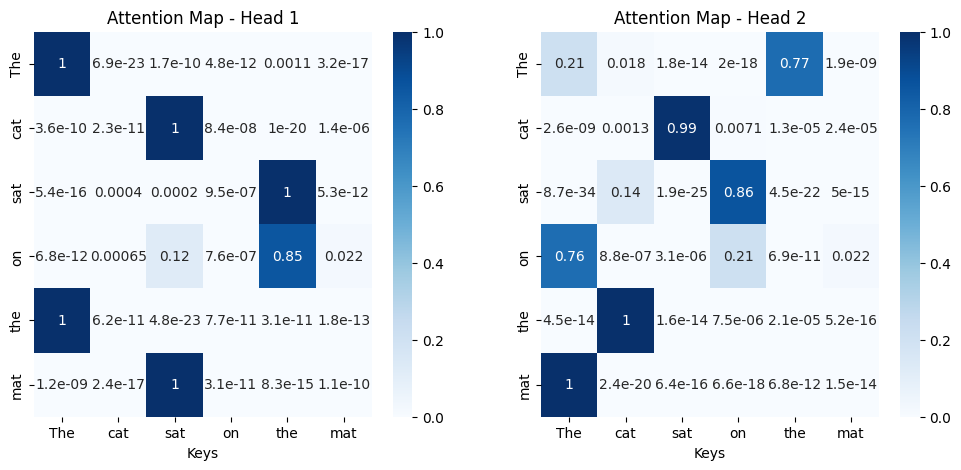

In [23]:
# Let's visualize the attention maps for both heads side-by-side
fig, axes = plt.subplots(1, num_heads, figsize=(12, 5))

for h in range(num_heads):
    sns.heatmap(
        distributions[h].detach().numpy(),
        annot=True,
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="Blues",
        cbar=True,
        vmin=0,
        vmax=1,
        ax=axes[h]
    )
    axes[h].set_title(f"Attention Map - Head {h+1}")
    axes[h].set_xlabel("Keys")